In [28]:
import os

# 设置 Hugging Face 镜像
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

# 显式修正 Hugging Face Hub 的 Endpoint
import huggingface_hub.constants as hf_constants

hf_constants.ENDPOINT = os.environ["HF_ENDPOINT"]

print("环境变量：", os.environ["HF_ENDPOINT"])
print("实际使用地址：", hf_constants.ENDPOINT)

环境变量： https://hf-mirror.com
实际使用地址： https://hf-mirror.com


In [29]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from chronos import Chronos2Pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.14.1+cu126
CUDA available: True
Device: cuda
GPU: Tesla P100-PCIE-16GB


In [30]:
MODEL_NAME = "amazon/chronos-2"

pipeline = Chronos2Pipeline.from_pretrained(
    MODEL_NAME,
    device_map=DEVICE
)

print("Chronos-2 loaded successfully!")

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 1038.42it/s]


Chronos-2 loaded successfully!


In [31]:
import os

print("当前工作目录：", os.getcwd())
print("当前目录内容：", os.listdir())

DATA_PATH = "../data/parking.csv"
TIMESTAMP_COL = "timestamp"
TARGET_COL = "occupancy_rate"

df = pd.read_csv(DATA_PATH)
df[TIMESTAMP_COL] = pd.to_datetime(df[TIMESTAMP_COL])
df = df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print(f"Number of rows: {len(df)}")
display(df.head())
display(df[[TIMESTAMP_COL, TARGET_COL]].describe(include="all"))

当前工作目录： /tmp/pycharm_project_8272a359/notebooks
当前目录内容： ['parking_prediction.csv', 'chronos_test.ipynb', 'chronos_backtest_predictions.csv', 'chronos_backtest_metrics.csv']
Number of rows: 4033


,timestamp,occupancy_rate
0,2026-10-19 00:00:00,0.1649
1,2026-10-19 00:05:00,0.1459
2,2026-10-19 00:10:00,0.1694
3,2026-10-19 00:15:00,0.1957
4,2026-10-19 00:20:00,0.1430


,timestamp,occupancy_rate
count,4033,4033.000000
mean,2026-10-25 23:59:59.999999744,0.227299
min,2026-10-19 00:00:00,0.020000
25%,2026-10-22 12:00:00,0.122200
50%,2026-10-26 00:00:00,0.171400
75%,2026-10-29 12:00:00,0.303700
max,2026-11-02 00:00:00,0.722400
std,NaN,0.165518


In [32]:
series_df = df[[TIMESTAMP_COL, TARGET_COL]].copy()
series_df[TARGET_COL] = pd.to_numeric(series_df[TARGET_COL], errors="coerce")
series_df = series_df.dropna().sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Missing values:", series_df.isna().sum().to_dict())
print("Min occupancy:", series_df[TARGET_COL].min())
print("Max occupancy:", series_df[TARGET_COL].max())

if not series_df[TARGET_COL].between(0, 1).all():
    print("Warning: occupancy is not fully within 0~1. Please confirm whether the unit is percentage.")

display(series_df.head())

Missing values: {'timestamp': 0, 'occupancy_rate': 0}
Min occupancy: 0.02
Max occupancy: 0.7224


,timestamp,occupancy_rate
0,2026-10-19 00:00:00,0.1649
1,2026-10-19 00:05:00,0.1459
2,2026-10-19 00:10:00,0.1694
3,2026-10-19 00:15:00,0.1957
4,2026-10-19 00:20:00,0.1430


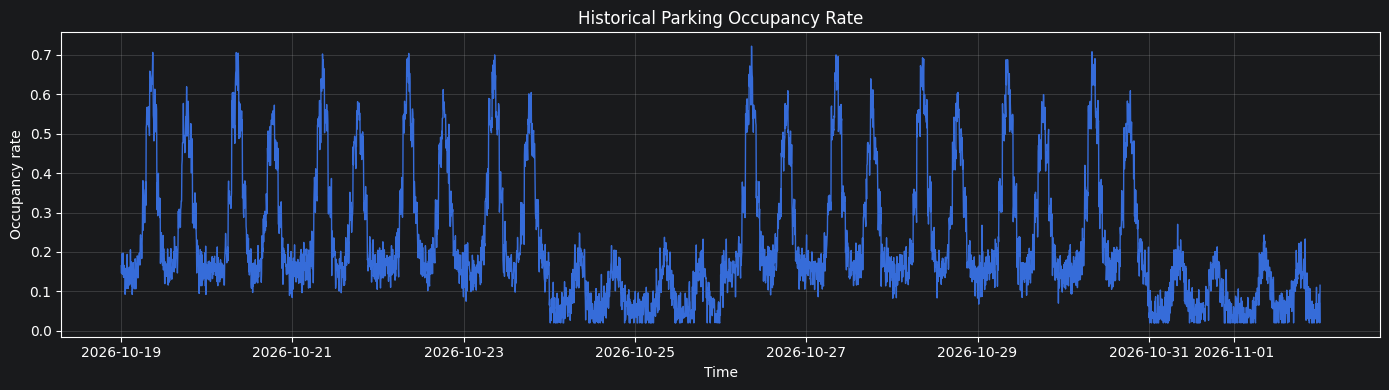

In [33]:
plt.figure(figsize=(14, 4))
plt.plot(series_df[TIMESTAMP_COL], series_df[TARGET_COL], linewidth=1)
plt.title("Historical Parking Occupancy Rate")
plt.xlabel("Time")
plt.ylabel("Occupancy rate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
PREDICTION_LENGTH = 12
PARKING_ID = "parking_001"

context_df = pd.DataFrame({
    "id": PARKING_ID,
    "timestamp": series_df[TIMESTAMP_COL],
    "target": series_df[TARGET_COL]
})

prediction_df = pipeline.predict_df(
    context_df,
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="id",
    timestamp_column="timestamp",
    target="target"
)

display(prediction_df.tail(PREDICTION_LENGTH))

,id,timestamp,target_name,predictions,0.1,0.5,0.9
0,parking_001,2026-11-02 00:05:00,target,0.132828,0.078311,0.132828,0.184373
1,parking_001,2026-11-02 00:10:00,target,0.148120,0.089603,0.148120,0.197974
2,parking_001,2026-11-02 00:15:00,target,0.147567,0.090914,0.147567,0.195965
3,parking_001,2026-11-02 00:20:00,target,0.150692,0.094850,0.150692,0.195816
4,parking_001,2026-11-02 00:25:00,target,0.148564,0.094359,0.148564,0.192648
5,parking_001,2026-11-02 00:30:00,target,0.146520,0.093946,0.146520,0.189931
6,parking_001,2026-11-02 00:35:00,target,0.141462,0.090755,0.141462,0.185502
7,parking_001,2026-11-02 00:40:00,target,0.139769,0.088383,0.139769,0.181563
8,parking_001,2026-11-02 00:45:00,target,0.144112,0.092912,0.144112,0.185346
9,parking_001,2026-11-02 00:50:00,target,0.146585,0.095145,0.146585,0.188007


Forecast result columns: ['id', 'timestamp', 'target_name', 'predictions', '0.1', '0.5', '0.9']


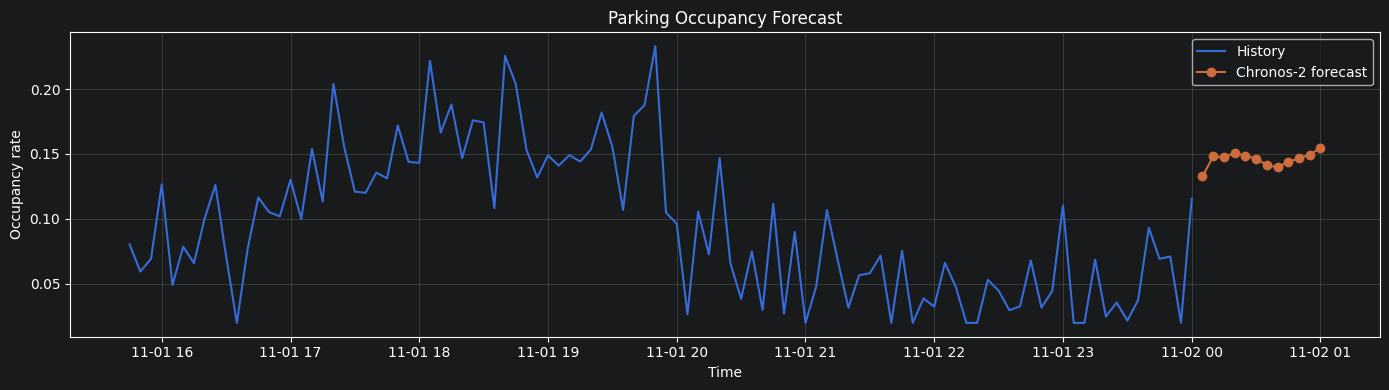

In [35]:
print("Forecast result columns:", prediction_df.columns.tolist())

future_df = prediction_df.tail(PREDICTION_LENGTH).copy()
median_candidates = ["0.5", "0.5_quantile", "target", "predictions"]
MEDIAN_COL = next((c for c in median_candidates if c in future_df.columns), None)

if MEDIAN_COL is None:
    numeric_cols = future_df.select_dtypes(include="number").columns.tolist()
    if not numeric_cols:
        raise ValueError("No numeric forecast column found. Check prediction_df.columns.")
    MEDIAN_COL = numeric_cols[-1]
    print(f"Median column not identified, falling back to numeric column: {MEDIAN_COL}")

plt.figure(figsize=(14, 4))
plt.plot(series_df[TIMESTAMP_COL].tail(100), series_df[TARGET_COL].tail(100), label="History")
plt.plot(future_df["timestamp"], future_df[MEDIAN_COL], marker="o", label="Chronos-2 forecast")
plt.title("Parking Occupancy Forecast")
plt.xlabel("Time")
plt.ylabel("Occupancy rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
OUTPUT_PATH = "parking_prediction.csv"
prediction_df.to_csv(OUTPUT_PATH, index=False)
print(f"Forecast results saved to: {OUTPUT_PATH}")

Forecast results saved to: parking_prediction.csv


In [37]:

# ==========================================
# Chronos-2 回测：计算 MAE、RMSE、MAPE
# ==========================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. 设置回测参数
PREDICTION_LENGTH = 12
PARKING_ID = "parking_001"

# 取最后12个时间点作为测试集
train_df = series_df.iloc[:-PREDICTION_LENGTH].copy()
test_df = series_df.iloc[-PREDICTION_LENGTH:].copy()

print("历史数据量：", len(train_df))
print("测试数据量：", len(test_df))

# 2. 构造历史输入
context_df = pd.DataFrame({
    "id": PARKING_ID,
    "timestamp": train_df[TIMESTAMP_COL],
    "target": train_df[TARGET_COL]
})

# 3. 使用 Chronos-2 预测测试集
backtest_prediction = pipeline.predict_df(
    context_df,
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="id",
    timestamp_column="timestamp",
    target="target"
)

print("预测结果字段：", backtest_prediction.columns.tolist())

# 4. 提取中位数预测值
if "0.5" not in backtest_prediction.columns:
    raise ValueError(
        "没有找到0.5分位数列，请检查预测结果字段。"
    )

forecast_df = backtest_prediction[
    ["timestamp", "0.5"]
].copy()

forecast_df = forecast_df.rename(
    columns={"0.5": "prediction"}
)

# 5. 与真实值对齐
evaluation_df = test_df[
    [TIMESTAMP_COL, TARGET_COL]
].merge(
    forecast_df,
    left_on=TIMESTAMP_COL,
    right_on="timestamp",
    how="inner"
)

evaluation_df = evaluation_df.rename(
    columns={TARGET_COL: "actual"}
)

if len(evaluation_df) != PREDICTION_LENGTH:
    raise ValueError(
        f"预测与真实值匹配数量不正确：{len(evaluation_df)}"
    )

# 6. 计算指标
y_true = evaluation_df["actual"].to_numpy()
y_pred = evaluation_df["prediction"].to_numpy()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE：忽略真实值为0的点
mask = np.abs(y_true) > 1e-8
mape = (
    np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    if mask.any() else np.nan
)

print("\n========== Chronos-2 回测结果 ==========")
print(f"MAE:  {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAPE: {mape:.4f}%")

# 7. 保存结果
evaluation_df.to_csv(
    "chronos_backtest_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

metrics_df = pd.DataFrame([{
    "Model": "Chronos-2",
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape
}])

metrics_df.to_csv(
    "chronos_backtest_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

display(evaluation_df)
display(metrics_df)


历史数据量： 4021
测试数据量： 12
预测结果字段： ['id', 'timestamp', 'target_name', 'predictions', '0.1', '0.5', '0.9']

========== Chronos-2 回测结果 ==========
MAE:  0.022800
RMSE: 0.027123
MAPE: 64.6546%


,timestamp,actual,prediction
0,2026-11-01 23:05:00,0.0200,0.045369
1,2026-11-01 23:10:00,0.0200,0.044979
2,2026-11-01 23:15:00,0.0687,0.043124
3,2026-11-01 23:20:00,0.0249,0.044978
4,2026-11-01 23:25:00,0.0357,0.042374
5,2026-11-01 23:30:00,0.0218,0.038720
6,2026-11-01 23:35:00,0.0374,0.036216
7,2026-11-01 23:40:00,0.0932,0.035549
8,2026-11-01 23:45:00,0.0693,0.036169
9,2026-11-01 23:50:00,0.0711,0.043240


,Model,MAE,RMSE,MAPE
0,Chronos-2,0.0228,0.027123,64.654637


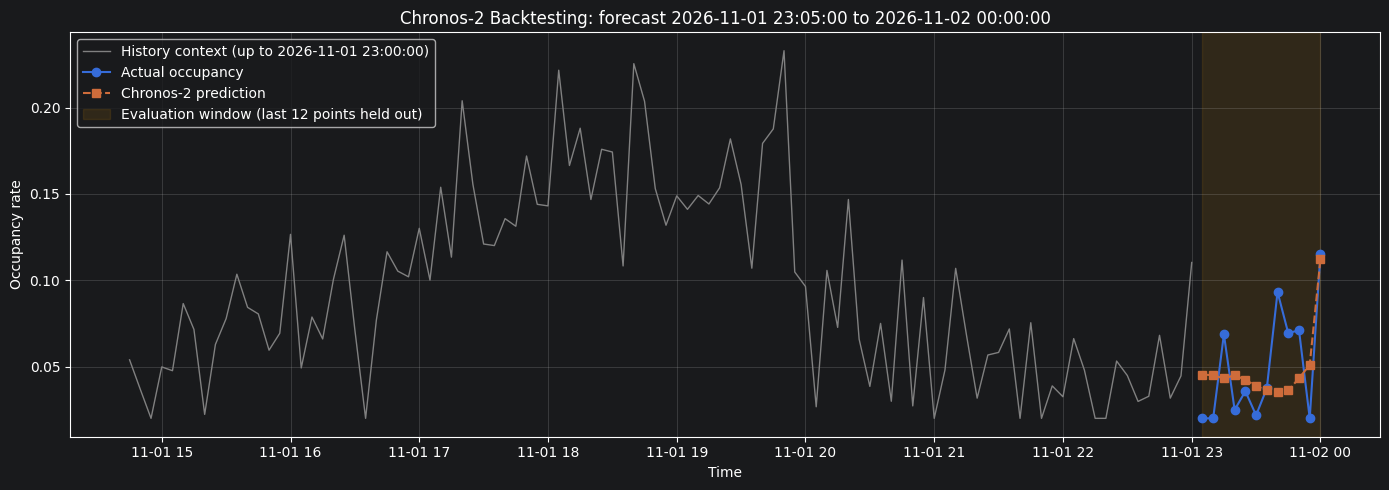

In [38]:
context_tail = train_df.tail(100)

plt.figure(figsize=(14, 5))
plt.plot(
    context_tail[TIMESTAMP_COL],
    context_tail[TARGET_COL],
    color="gray",
    linewidth=1,
    label="History context (up to " + str(train_df[TIMESTAMP_COL].iloc[-1]) + ")"
)
plt.plot(
    evaluation_df["timestamp"],
    evaluation_df["actual"],
    marker="o",
    label="Actual occupancy"
)
plt.plot(
    evaluation_df["timestamp"],
    evaluation_df["prediction"],
    marker="s",
    linestyle="--",
    label="Chronos-2 prediction"
)
plt.axvspan(
    evaluation_df["timestamp"].min(),
    evaluation_df["timestamp"].max(),
    color="orange",
    alpha=0.10,
    label="Evaluation window (last 12 points held out)"
)
plt.title(
    "Chronos-2 Backtesting: forecast "
    + str(evaluation_df["timestamp"].min())
    + " to "
    + str(evaluation_df["timestamp"].max())
)
plt.xlabel("Time")
plt.ylabel("Occupancy rate")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
